In [2]:
# Importation de PyTorch, la bibliothèque de deep learning
import torch

In [3]:
# Choix du périphérique de calcul : GPU (cuda) s'il est disponible, sinon CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Génération de 50 valeurs régulièrement espacées entre -2 et 2
# unsqueeze(1) transforme le vecteur (50,) en matrice colonne (50, 1),
# format attendu par les couches nn.Linear (une ligne = un exemple)
x = torch.linspace(-2, 2, 50).unsqueeze(1)

In [5]:
# Affichage du tenseur x pour vérifier son contenu et sa forme
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [6]:
# Création d'un bruit gaussien (moyenne 0, écart-type 0.6) de même forme que x
noise =0.6 * torch.randn_like(x)
# Construction de la cible : relation linéaire y = 3x + 2, perturbée par le bruit
# Le modèle devra retrouver la pente (3) et l'ordonnée à l'origine (2)
y = 3 * x +2 + noise

In [7]:
# Importation de matplotlib pour la visualisation des données
import matplotlib.pyplot as plt

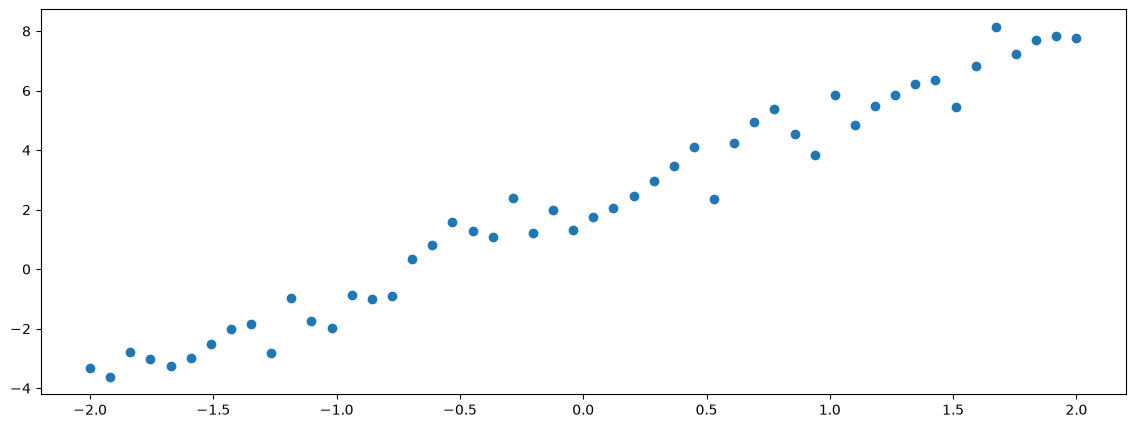

In [8]:
# Création d'une figure de 14 x 5 pouces
plt.figure(figsize=(14, 5))
# Nuage de points pour visualiser les données (x, y) générées
plt.scatter(x,y)

In [9]:
# Importation du module des réseaux de neurones de PyTorch
import torch.nn as nn

In [10]:
#creation du model
# Couche linéaire avec 1 entrée et 1 sortie : y_pred = w * x + b
# (w et b sont initialisés aléatoirement puis appris pendant l'entraînement)
model =nn.Linear(1, 1)

In [36]:
# Fonction de perte : erreur quadratique moyenne (MSE), adaptée à la régression
loss_function = nn.MSELoss()
# Optimiseur Adam qui met à jour les paramètres du modèle (w, b) avec un taux d'apprentissage de 0.01
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
# Nombre d'itérations d'entraînement (passages complets sur les données)
EPOCHS = 100
# Liste pour stocker la valeur de la perte à chaque époque
losses = []
# Boucle d'entraînement
for epoch in range(EPOCHS):
    # Propagation avant : calcul des prédictions du modèle
    y_pred = model(x)
    # Calcul de l'erreur entre les prédictions et les vraies valeurs
    loss = loss_function(y_pred, y)
    # Remise à zéro des gradients (sinon ils s'accumulent d'une itération à l'autre)
    optimizer.zero_grad()
    # Rétropropagation : calcul des gradients de la perte par rapport à w et b
    loss.backward()
    # Mise à jour des paramètres selon les gradients calculés
    optimizer.step()
    # Sauvegarde de la perte (item() convertit le tenseur en nombre Python)
    losses.append(loss.item())
    # Affichage de la perte toutes les 100 époques
    if epoch % 100 == 0:
        print(f"Epoch {epoch}/{EPOCHS}, Loss={loss.item()}")

Epoch 0/100, Loss=0.3422253429889679


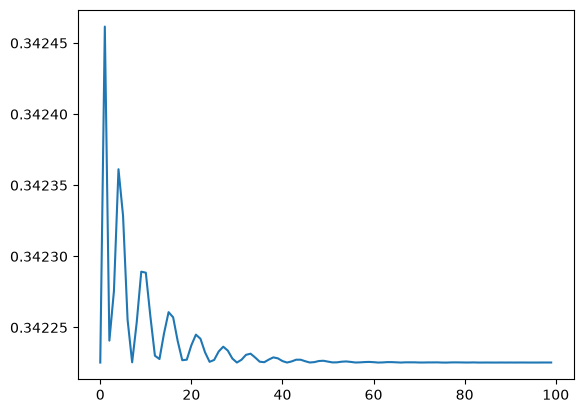

In [37]:
# Courbe d'évolution de la perte au fil des époques
# (elle doit diminuer si le modèle apprend correctement)
plt.plot(losses)


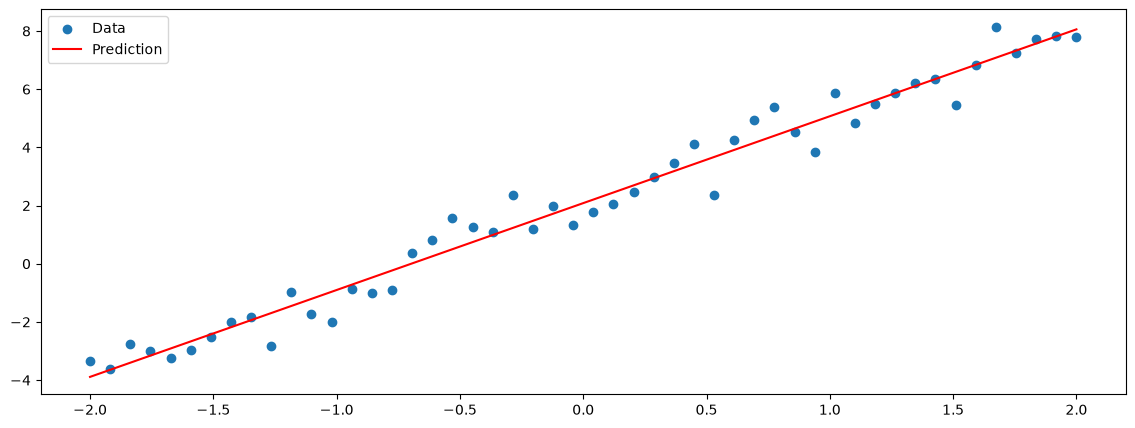

In [26]:
# Mode inférence : désactive le calcul des gradients (plus rapide, moins de mémoire)
with torch.inference_mode():
    # Prédictions du modèle entraîné sur toutes les données
    y_pred = model(x)
    # Création de la figure
    plt.figure(figsize=(14, 5))
    # Points réels (données bruitées)
    plt.scatter(x, y, label="Data")
    # Droite prédite par le modèle, en rouge
    plt.plot(x, y_pred, color='red', label="Prediction")
    # Affichage de la légende puis du graphique
    plt.legend()
    plt.show()

In [18]:
# Importation de la métrique R² (coefficient de détermination) depuis torcheval
from torcheval.metrics import R2Score       

c:\Users\hp\Documents\HESTIM 2\DEEP LEARNING\pytorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [38]:
# Création de l'objet métrique R²
r2_score = R2Score()
# Ajout des données à évaluer (prédictions et valeurs réelles)
r2_score.update(y,y_pred)
# Calcul du score R² : 1 = prédiction parfaite, 0 = pas mieux que la moyenne
score = r2_score.compute()

In [39]:
# Affichage du score R² obtenu
print(score)

tensor(0.9724)
